# Figure 4e. Recipient-cell pathways linked to neuron-initiated *cis*-*trans* associations

Reactome over-representation results for the *trans* genes in astrocyte, microglia, oligodendrocyte and OPC recipients of *cis*-excitatory-neuron signals. Dot size is the number of overlapping genes and colour is -log10 nominal P. For each cell type the figure shows the five pathways with the smallest nominal P plus a few additional pathways the authors picked on biological grounds from those with nominal P < 0.01 (column `selection_reason`); several of these have q > 0.1. A pathway selected in two cell types (Post-translational modification) shares one row.

Input: `data/Figure_4e_recipient_pathways.rds`

In [1]:
library(ggplot2)
library(scales)
res <- readRDS("data/Figure_4e_recipient_pathways.rds")
res[, c("trans_cell", "pathway_label", "selection_reason", "overlap", "p_value", "q_value")]

trans_cell,pathway_label,selection_reason,overlap,p_value,q_value
<fct>,<chr>,<chr>,<int>,<dbl>,<dbl>
Astrocyte,Asparagine N-linked glycosylation,Top 5 by nominal P value,40,2.785232e-05,0.038766346
Astrocyte,Post-translational modification,Top 5 by nominal P value,141,3.346253e-05,0.038766346
Astrocyte,ER-to-Golgi anterograde transport,Top 5 by nominal P value,23,9.631151e-05,0.074384589
Astrocyte,Golgi transport and subsequent processing,Top 5 by nominal P value,26,1.438544e-04,0.083327657
Astrocyte,COPI-mediated anterograde transport,Top 5 by nominal P value,16,2.352711e-04,0.090853845
Astrocyte,Monoamine oxidase-mediated dopamine degradation,Biology-guided,2,5.147444e-03,0.298165699
Astrocyte,Cholesterol biosynthesis,Biology-guided,6,7.308638e-03,0.321756619
Astrocyte,SREBP-mediated transcriptional activation,Biology-guided,6,8.936078e-03,0.321756619
Microglia,Chromatin-modifying enzymes,Top 5 by nominal P value,25,5.527047e-05,0.018228202


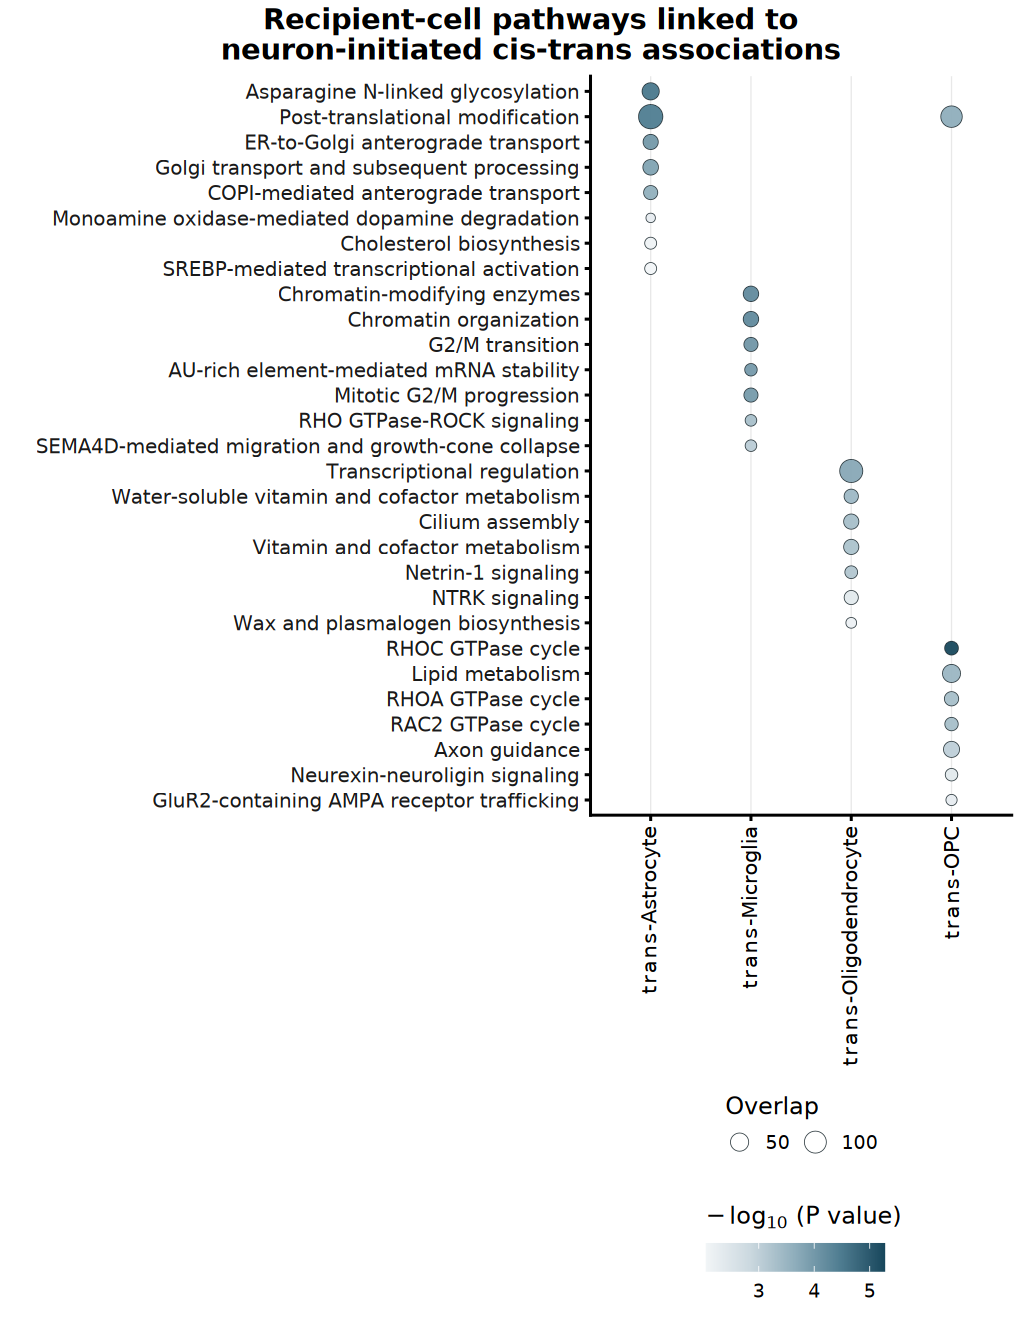

In [2]:
path_levels <- unique(res$pathway_label)
res$pathway_label <- factor(res$pathway_label, levels = rev(path_levels))
res$neglog10_p <- -log10(res$p_value)
trans_lab <- c("Astrocyte" = "italic(trans)*'-Astrocyte'", "Microglia" = "italic(trans)*'-Microglia'",
               "Oligodendrocyte" = "italic(trans)*'-Oligodendrocyte'", "OPC" = "italic(trans)*'-OPC'")

p <- ggplot(res, aes(x = trans_cell, y = pathway_label)) +
  geom_point(aes(size = overlap, fill = neglog10_p), shape = 21, colour = "#263238",
             stroke = 0.26, alpha = 0.94) +
  scale_x_discrete(labels = function(x) parse(text = trans_lab[x]), drop = FALSE) +
  scale_size_continuous(range = c(2.2, 6.4), breaks = pretty_breaks(n = 4), name = "Overlap") +
  scale_fill_gradientn(colours = c("#F2F5F7", "#CBD8DF", "#8EADBB", "#4F7D91", "#17475C"),
                       breaks = pretty_breaks(n = 3), name = expression(-log[10]~"(P value)")) +
  labs(title = "Recipient-cell pathways linked to\nneuron-initiated cis-trans associations",
       x = NULL, y = NULL) +
  theme_classic(base_size = 14) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold"),
        plot.title.position = "plot",
        axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 12),
        axis.text.y = element_text(size = 11.5, colour = "grey10"),
        panel.grid.major.x = element_line(colour = "#E8E8E8", linewidth = 0.28),
        legend.position = "bottom", legend.box = "vertical",
        plot.margin = margin(5, 5, 5, 30)) +
  guides(size = guide_legend(order = 1, nrow = 1, title.position = "top",
                             override.aes = list(fill = "white")),
         fill = guide_colourbar(order = 2, title.position = "top",
                                barwidth = grid::unit(3.8, "cm")))

options(repr.plot.width = 8.5, repr.plot.height = 11)
p